In [1]:
import sys
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 
import numpy as np
from scipy import stats

from tqdm import tqdm

###changes default of autoreloader to continually reload (2) rather than only on restart
####good for debuggin but does slow code as it is continully reloading modules
%load_ext autoreload
%autoreload 2

###can also use dir() to check what is in function and that new params have been loaded

import os
import glob


#desktop = os.path.join(os.path.join(os.environ['USERPROFILE']), 'Desktop') 
plot_path="../output/plots"
mypath = plot_path

import sys
sys.path.append("../src")
from Branch_analysis import branch_dsc, update_DSCs, update_compartments
from Summary_analysis import summary_dsc

Import Data

In [2]:
EMdata = {}

#root = 'M:/Tony/Bonn/Data/Distal_Dendrite/Morphology/EM/classicFix/data/'
root = 'M:/Tony/Bonn/Data/Distal_Dendrite/Morphology/repo_data/EM/'

folder = root+'DD0075_E5/tables/'
file = 'D1_binary - Local Diameter.csv'
EMdata['branch1'] = {'path':folder+file}
EMdata['branch1']['ex_factor'] = 1
EMdata['branch1']['res'] = 0.01 #10nm voxel

file = 'D2_binary - Local Diameter.csv'
EMdata['branch2'] = {'path':folder+file}
EMdata['branch2']['ex_factor'] = 1
EMdata['branch2']['res'] = 0.01 #10nm voxel

file = 'D4_binary - Local Diameter.csv'
EMdata['branch4'] = {'path':folder+file}
EMdata['branch4']['ex_factor'] = 1
EMdata['branch4']['res'] = 0.01 #10nm voxel

file = 'D5_binary - Local Diameter.csv'
EMdata['branch5'] = {'path':folder+file}
EMdata['branch5']['ex_factor'] = 1
EMdata['branch5']['res'] = 0.01 #10nm voxel


#03 replaced area missing due to bubble in EM stack with binary segemted above
#06 corrected skeleton
    
#07 corrected skeleton
#09 replaced area missing due to bubble in EM stack with binary segment 
    

file = '03 - Local Diameter.csv'
EMdata['branch3'] = {'path':folder+file}
EMdata['branch3']['ex_factor'] = 1
EMdata['branch3']['res'] = 0.01 #50nm voxel

EMdata['branch6'] = {'path':folder+'06 - Local Diameter.csv'}
EMdata['branch6']['ex_factor'] = 1
EMdata['branch6']['res'] = 0.01 #50nm voxel

EMdata['branch7'] = {'path':folder+'07 - Local Diameter.csv'}
EMdata['branch7']['ex_factor'] = 1
EMdata['branch7']['res'] = 0.01 #50nm voxel

EMdata['branch8'] = {'path':folder+'08 - Local Diameter.csv'}
EMdata['branch8']['ex_factor'] = 1
EMdata['branch8']['res'] = 0.01 #50nm voxel

EMdata['branch9'] = {'path':folder+'09 - Local Diameter.csv'}
EMdata['branch9']['ex_factor'] = 1
EMdata['branch9']['res'] = 0.01 #50nm voxel


folder = root+'1922_DistalMolLayer/tables/'
file = 'object02 - Local Diameter.csv'
EMdata['branch12'] = {'path':folder+file}
EMdata['branch12']['ex_factor'] = 1
EMdata['branch12']['res'] = 0.01 #50nm voxel

file = 'object03 - Local Diameter.csv'
EMdata['branch13'] = {'path':folder+file}
EMdata['branch13']['ex_factor'] = 1
EMdata['branch13']['res'] = 0.01 #50nm voxel

file = 'object04 - Local Diameter.csv'
EMdata['branch14'] = {'path':folder+file}
EMdata['branch14']['ex_factor'] = 1
EMdata['branch14']['res'] = 0.01 #50nm voxel

file = 'object07 - Local Diameter.csv'
EMdata['branch17'] = {'path':folder+file}
EMdata['branch17']['ex_factor'] = 1
EMdata['branch17']['res'] = 0.01 #50nm voxel

file = 'object092 - Local Diameter.csv'
EMdata['branch19'] = {'path':folder+file}
EMdata['branch19']['ex_factor'] = 1
EMdata['branch19']['res'] = 0.01 #50nm voxel

file = 'object10 - Local Diameter.csv'
EMdata['branch20'] = {'path':folder+file}
EMdata['branch20']['ex_factor'] = 1
EMdata['branch20']['res'] = 0.01 #50nm voxel

file = 'object11 - Local Diameter.csv'
EMdata['branch21'] = {'path':folder+file}
EMdata['branch21']['ex_factor'] = 1
EMdata['branch21']['res'] = 0.01 #50nm voxel

file = 'object12 - Local Diameter.csv'
EMdata['branch22'] = {'path':folder+file}
EMdata['branch22']['ex_factor'] = 1
EMdata['branch22']['res'] = 0.01 #50nm voxel

file = 'object15 - Local Diameter.csv'
EMdata['branch25'] = {'path':folder+file}
EMdata['branch25']['ex_factor'] = 1
EMdata['branch25']['res'] = 0.01 #50nm voxel


In [3]:
dataSet=EMdata
for name, dendrite in tqdm(dataSet.items()):
    #print(name)
    #print(data[name]['path'])
    
    file_path = dendrite['path']#+dendrite['file']
    dataSet[name] = branch_dsc(file_path, dataSet[name]['res'], dataSet[name]['ex_factor'])

100%|██████████| 18/18 [00:32<00:00,  1.80s/it]


In [4]:
### add manual to the data dictionary 
# ##add manual branch5 goes below x2 threshold but sligth increase excludes it from algorythm eventhough still DSC in my opinion  
branch=EMdata['branch4']
DSC=branch['data'][120:275].copy()
DSC.diam*=1/branch['ex_factor']   #if the DSCs overlap each other the scaling applied again. Separate DSC from orig data
DSC.smth*=1/branch['ex_factor']
DSC.length*=branch['res']/branch['ex_factor']
DSC.pt_distance*=branch['res']/branch['ex_factor']
branch['DSCs'].append(DSC) 

branch=EMdata['branch5']
DSC=branch['data'][360:570].copy()
DSC.diam*=1/branch['ex_factor']   #if the DSCs overlap each other the scaling applied again. Separate DSC from orig data
DSC.smth*=1/branch['ex_factor']
DSC.length*=branch['res']/branch['ex_factor']
DSC.pt_distance*=branch['res']/branch['ex_factor']
branch['DSCs'].append(DSC)  

del EMdata['branch14']['DSCs'][0] #the auto detected DSC is too long past the DSC -shortened
branch=EMdata['branch14']
DSC=branch['data'][364:450].copy()
DSC.diam*=1/branch['ex_factor']   #if the DSCs overlap each other the scaling applied again. Separate DSC from orig data
DSC.smth*=1/branch['ex_factor']
DSC.length*=branch['res']/branch['ex_factor']
DSC.pt_distance*=branch['res']/branch['ex_factor']
branch['DSCs'].append(DSC)  


##maybe other DSCs in branch 17 object7 but difficult to confirm without proper registration.
del EMdata['branch17']['DSCs'][0]
del EMdata['branch17']['DSCs'][1]

del EMdata['branch20']['DSCs'][0]

##weird branch and then jumps from one branch to another need to check EM
del EMdata['branch25']['DSCs'][1]

In [10]:
update_DSCs(EMdata['branch4'])
update_DSCs(EMdata['branch5'])
update_DSCs(EMdata['branch17'])
update_DSCs(EMdata['branch20'])
update_DSCs(EMdata['branch25'])

update_DSCs(EMdata['branch14'])

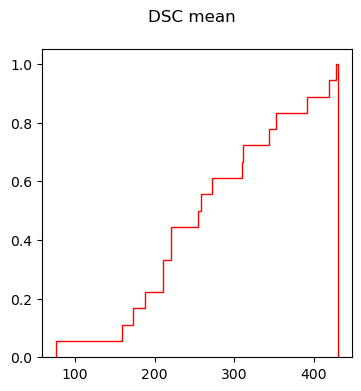

In [13]:
#select property to plot [mean, lenght]
parameter='mean'

df= summary_dsc(EMdata, parameter)

n_bins=200
fig, ax = plt.subplots(figsize=(4, 4))
fig.suptitle('DSC '+parameter)

df=df.stack().reset_index(drop=True)

n, bins, patches = ax.hist(df, n_bins, color='red', density=True, histtype='step', cumulative=True)
#ax.set_xlim([0,10])

fig.savefig(mypath+'/EM_DSC_diam_Cumulative.svg', bbox_inches = 'tight')